# Sudan regional recovery — six completed cases

**INTERIM RESULTS: 6 of 12 planned cases.** This notebook contains the three policy comparisons under restricted and selective recovery. Each included case passed investment optimization, an independent 8,760-hour fixed-investment replay, and saved-output physical, cost and coverage checks. Restored recovery and the three robustness checks are **not included**. This is a frozen reading copy; see the parent folder's live progress page for the continuing batch.

**Question:** Where, and under what recovery conditions, are grid rehabilitation, mini-grids or standalone systems the least-cost way to provide reliable electricity in Sudan?

**Region:** Northern, River Nile, Khartoum, Gezira, White Nile and Sennar. All 11,268 source clusters are represented in 36 planning zones. The 10,078,666 potential building connections are **not verified households or newly connected customers**. National generation and electricity transfers outside the six states remain represented.

The reference/weather year is 2022. Recovery conditions are hypothetical; hourly residential demand is an assumed service profile. Numerical validation is not field validation. Monetary values follow the project's constant-2025 USD lifecycle ledger.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display,Markdown
HERE=Path.cwd()
if not (HERE/'snapshot.json').exists():
    ROOT=next(p for p in [HERE,*HERE.parents] if (p/'data/regional_model/config.json').exists())
    HERE=ROOT/'research/regional_joint_study/interim_6_cases'
D=HERE/'data';F=HERE/'figures';F.mkdir(exist_ok=True)
snapshot=json.loads((HERE/'snapshot.json').read_text())
summary=pd.read_csv(D/'summary.csv');choices=pd.read_csv(D/'choices.csv')
checks=pd.read_csv(D/'validation.csv');cross=pd.read_csv(D/'crosswalk_36.csv.gz')
scenarios=['restricted','selective'];policies=['mixed','grid_led','decentralized']
policy_labels={'mixed':'Mixed least-cost','grid_led':'Grid-led','decentralized':'Decentralized-first'}
colors={'grid':'#426BA7','mini_grid':'#1C8D82','standalone':'#E0A324'}
labels={'grid':'Grid + local support','mini_grid':'Mini-grid','standalone':'Standalone'}
states=['Northern','River Nile','Khartoum','Gezira','White Nile','Sennar']
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def show(fig,name):
    fig.savefig(F/(name+'.png'),dpi=160,bbox_inches='tight')
    fig.savefig(F/(name+'.svg'),bbox_inches='tight',metadata={'Date':None})
    plt.show();plt.close(fig)
display(Markdown('Snapshot captured **'+snapshot['created_UTC']+'**. Reopening or rerunning this notebook does not run the optimization.'))
assert len(summary)==6 and len(checks)==12 and checks.passed.all()
summary['grid_share_percent']=100*summary.grid_connections/summary.potential_connections
table=summary[['scenario','policy','annual_system_cost_USD','initial_local_and_repair_USD','grid_share_percent','repair_investment_USD']].copy()
table['annual_system_cost_USD']/=1e9;table['initial_local_and_repair_USD']/=1e9;table['repair_investment_USD']/=1e6
table.columns=['Recovery','Policy','Annual cost (billion USD/year)','Initial local + repairs (billion USD)','Grid connections (%)','Backbone repair (million USD)']
display(table.style.format(precision=3))

Snapshot captured **2026-10-19T20:28:48.043548+00:00**. Reopening or rerunning this notebook does not run the optimization.

,Recovery,Policy,Annual cost (billion USD/year),Initial local + repairs (billion USD),Grid connections (%),Backbone repair (million USD)
0,restricted,mixed,3.888,17.966,70.923,0.000
1,restricted,grid_led,4.076,19.324,100.000,0.000
2,restricted,decentralized,4.322,20.366,0.000,0.000
3,selective,mixed,2.980,14.891,79.097,32.954
4,selective,grid_led,3.115,15.958,100.000,32.954
5,selective,decentralized,3.940,20.399,0.000,32.954


## 1. What the six cases compare

| Recovery | Backbone repair rule | Assumed local grid interruption |
|---|---|---|
| Restricted | No candidate repairs | 18:00–23:00 local time |
| Selective | Select repairs within $45 million | 19:00–21:00 local time |

Each recovery condition has **mixed least-cost**, **grid-led** and **decentralized-first** policies with identical service targets. The grid-led policy can size local PV and batteries; it does not mean electricity must come entirely from the grid. Decentralized-first chooses the cheaper independent mini-grid or standalone design for each zone. Mixed planning jointly selects grid service, grid-connected equipment and permitted backbone repairs alongside national dispatch. Off-grid designs are independently sized and separable under the stated model.

Existing regional residential consumption is removed from the national baseline before the selected local service is added. Nonresidential demand and outside-region loads remain. Total annual system costs include national background operation, so they are not simply a new-access budget.

In [2]:
coverage=pd.read_csv(D/'zones_36.csv').groupby('state')[['clusters','connections','baseline_residential_MWh','target_MWh']].sum().reindex(states)
display(coverage.style.format(precision=0,thousands=','))

,clusters,connections,baseline_residential_MWh,target_MWh
state,,,,
Northern,"1,345","642,743","300,314","300,314"
River Nile,"2,072","870,464","300,314","317,719"
Khartoum,"1,818","3,779,944","4,504,714","4,504,714"
Gezira,"2,842","2,663,000","750,786","971,995"
White Nile,"2,090","1,215,012","300,314","443,479"
Sennar,"1,101","907,503","225,236","331,239"


## 2. Maps for all six completed cases

Each point is a source cluster and inherits its planning-zone choice. These are geographic screening maps, not surveyed network routes or individual building recommendations. No administrative boundary or usable connection is inferred from a point's colour.

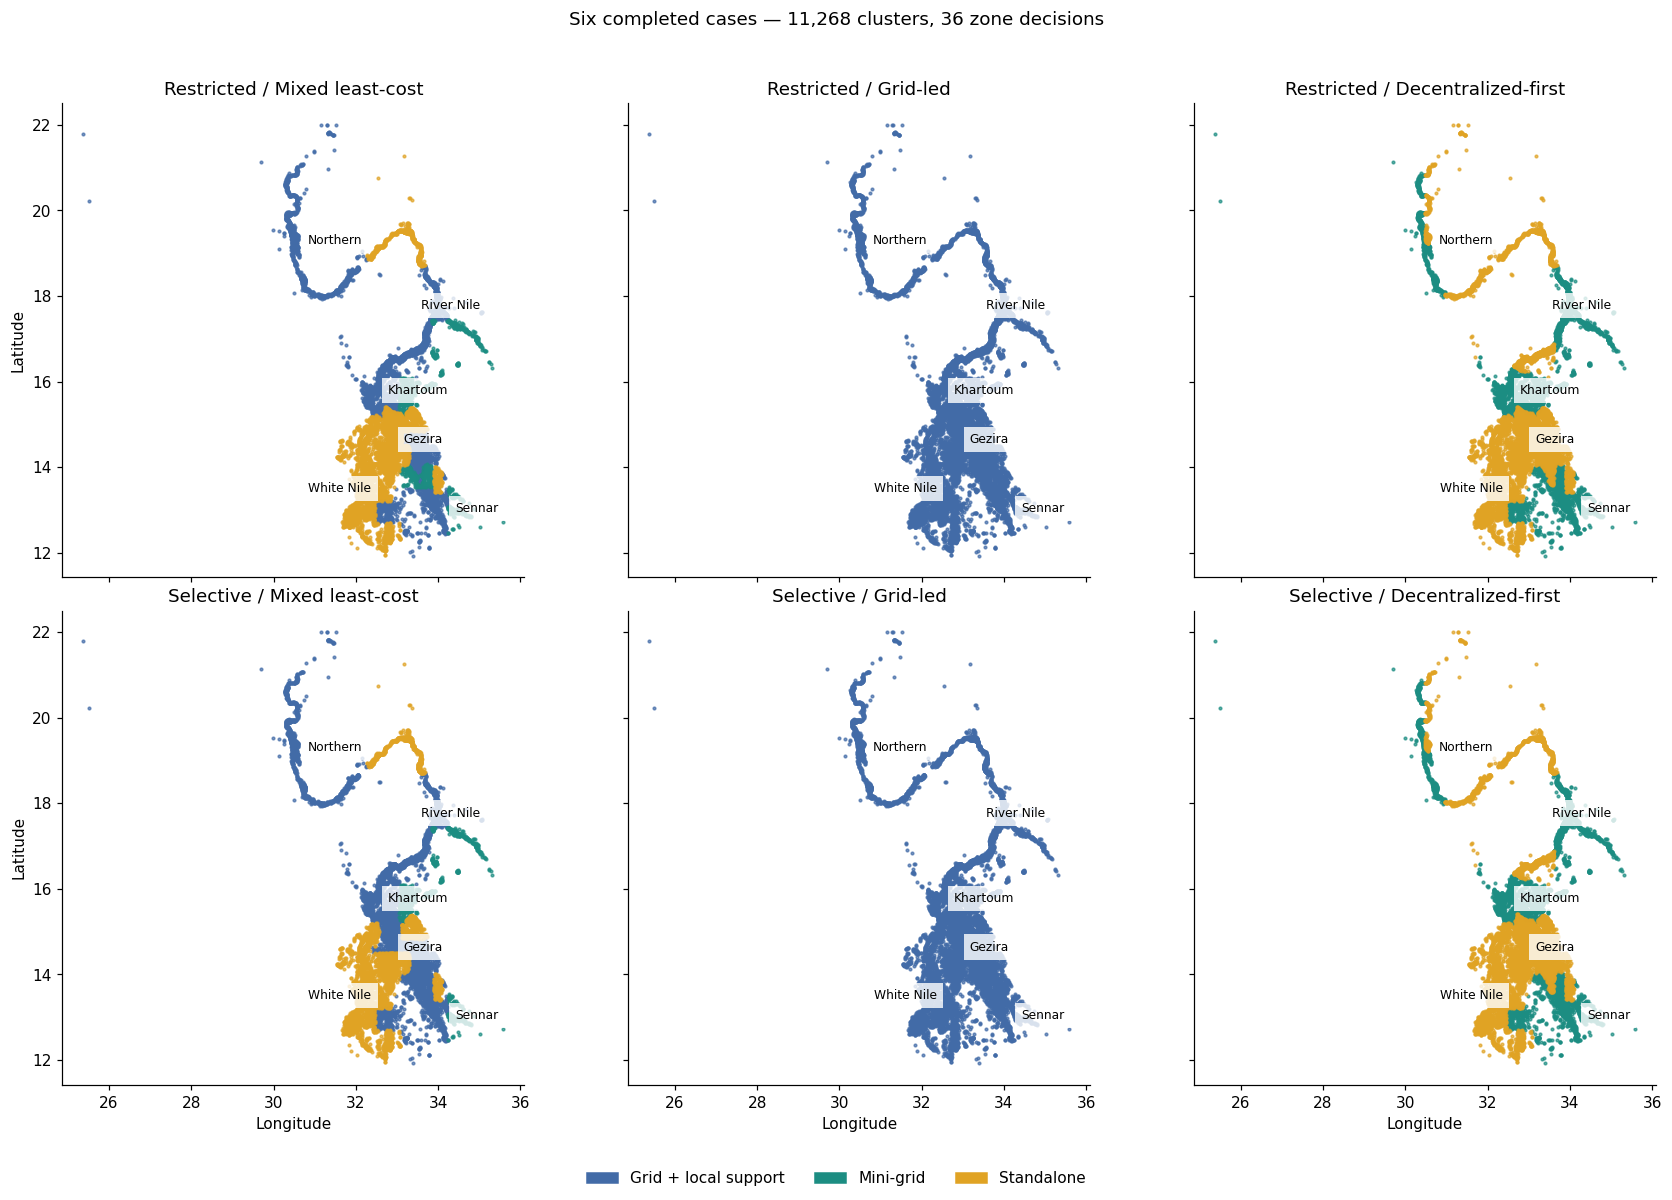

In [3]:
fig,axes=plt.subplots(2,3,figsize=(16,11),sharex=True,sharey=True)
for i,scenario in enumerate(scenarios):
    for j,policy in enumerate(policies):
        ax=axes[i,j];selected=choices[(choices.scenario==scenario)&(choices.policy==policy)]
        points=cross.merge(selected[['zone_id','mode']],on='zone_id',validate='many_to_one')
        assert len(points)==11268 and points['mode'].notna().all()
        for mode,color in colors.items():
            p=points[points['mode']==mode];ax.scatter(p.lon,p.lat,s=3,c=color,alpha=.7,rasterized=True)
        for state,g in points.groupby('admin_cgaz_1'):
            offset={'White Nile':(-40,0),'Sennar':(15,-10)}.get(state,(0,0))
            ax.annotate(state,(g.lon.mean(),g.lat.mean()),xytext=offset,textcoords='offset points',fontsize=8,bbox={'facecolor':'white','alpha':.8,'edgecolor':'none'})
        ax.set_title(scenario.capitalize()+' / '+policy_labels[policy]);ax.set_aspect(1/np.cos(np.radians(16)))
        if i==1:ax.set_xlabel('Longitude')
        if j==0:ax.set_ylabel('Latitude')
fig.legend(handles=[Patch(color=v,label=labels[k]) for k,v in colors.items()],loc='lower center',ncol=3,frameon=False)
fig.suptitle('Six completed cases — 11,268 clusters, 36 zone decisions')
fig.tight_layout(rect=[0,.045,1,.96]);show(fig,'six_case_maps')

## 3. Regional technology shares in mixed planning

Pies show shares of potential connections, not shares of energy. A grid-labelled zone may use substantial local solar and storage. Slices below 7% are left unlabelled for readability; the table gives the exact connection counts.

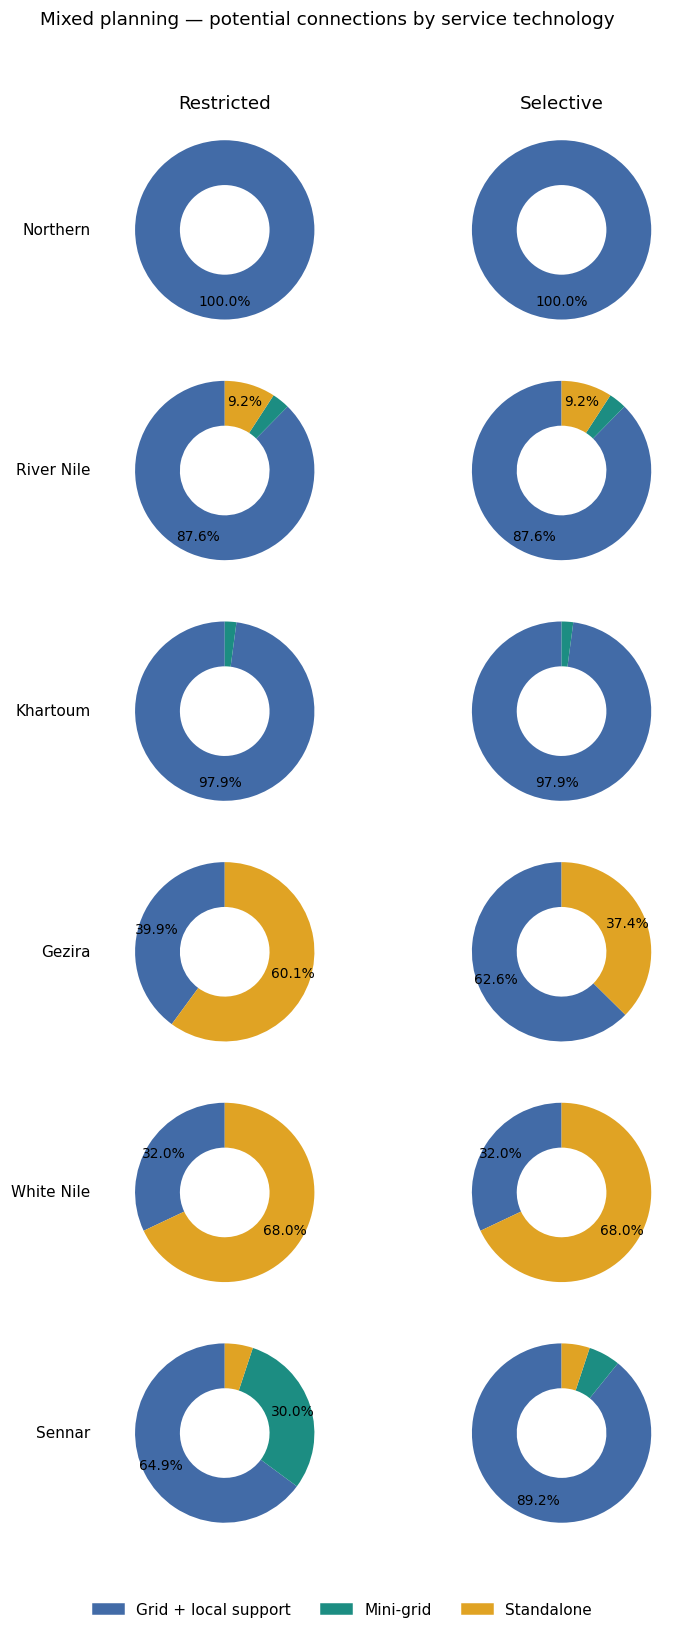

In [4]:
fig,axes=plt.subplots(6,2,figsize=(9,15))
mixed=choices[choices.policy=='mixed']
for i,state in enumerate(states):
    for j,scenario in enumerate(scenarios):
        ax=axes[i,j];d=mixed[(mixed.state==state)&(mixed.scenario==scenario)].groupby('mode').connections.sum().reindex(colors,fill_value=0)
        active=d[d>0]
        ax.pie(active,colors=[colors[k] for k in active.index],startangle=90,autopct=lambda v:f'{v:.1f}%' if v>=7 else '',pctdistance=.8,textprops={'fontsize':9},wedgeprops={'width':.5})
        if i==0:ax.set_title(scenario.capitalize())
        if j==0:ax.text(-1.5,0,state,ha='right',va='center')
fig.suptitle('Mixed planning — potential connections by service technology')
fig.legend(handles=[Patch(color=v,label=labels[k]) for k,v in colors.items()],loc='lower center',ncol=3,frameon=False)
fig.tight_layout(rect=[.12,.04,1,.96]);show(fig,'state_pies')
display(mixed.groupby(['scenario','state','mode']).connections.sum().unstack(fill_value=0).style.format(precision=0,thousands=','))

## 4. Policy costs, savings and repairs

Annual costs include lifecycle equipment, replacements, maintenance, local network/security allowances, fuel, national operation and annualized backbone repairs. Initial spending covers local systems and modeled repairs and excludes sunk national generating assets. The storage-charging tie-break is excluded from reported costs.

Savings intervals below use conservative solver objective bounds. An interval spanning zero does not establish a strict cost ranking. These are numerical bounds for this formulation, not uncertainty intervals for real-world costs.

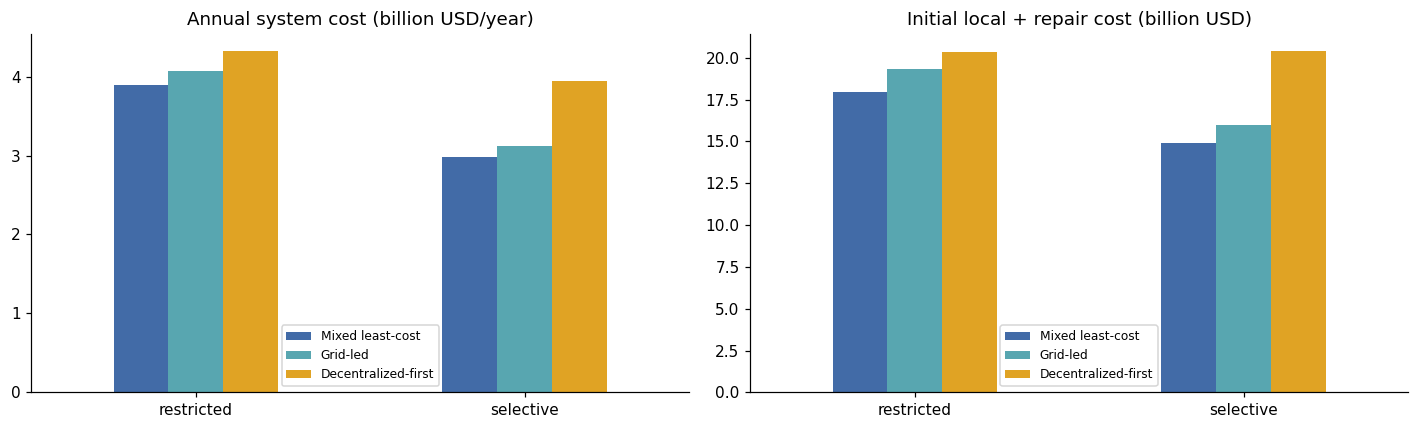

,Recovery,Compared with,Saving (million USD/year),Lower bound,Upper bound
0,restricted,Grid-led,187.864,187.044,188.684
1,restricted,Decentralized-first,434.149,433.325,434.970
2,selective,Grid-led,135.102,134.281,135.929
3,selective,Decentralized-first,960.329,959.504,961.155


,scenario,asset_id,reference_MW,available_fraction,selected,spend_USD
0,restricted,merowe_khartoum,700.00,0.10,0,0.00
1,restricted,atbara_khartoum,450.00,0.10,0,0.00
2,restricted,khartoum_kosti,300.00,0.10,0,0.00
3,restricted,khartoum_medani,300.00,0.10,0,0.00
12,selective,merowe_khartoum,700.00,0.10,1,"32,953,727.71"
13,selective,atbara_khartoum,450.00,0.10,0,0.00
14,selective,khartoum_kosti,300.00,0.10,0,0.00
15,selective,khartoum_medani,300.00,0.10,0,0.00


In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,col,title in [(axes[0],'annual_system_cost_USD','Annual system cost (billion USD/year)'),(axes[1],'initial_local_and_repair_USD','Initial local + repair cost (billion USD)')]:
    t=summary.pivot(index='scenario',columns='policy',values=col).reindex(scenarios)[policies]/1e9
    t.rename(columns=policy_labels).plot.bar(ax=ax,rot=0,color=['#426BA7','#58a6b0','#E0A324'])
    ax.set_title(title);ax.set_xlabel('');ax.legend(fontsize=8)
fig.tight_layout();show(fig,'policy_costs')
savings=[]
for scenario in scenarios:
    s=summary[summary.scenario==scenario].set_index('policy');a=s.loc['mixed']
    for p in ['grid_led','decentralized']:
        b=s.loc[p]
        savings.append({'Recovery':scenario,'Compared with':policy_labels[p],'Saving (million USD/year)':(b.annual_system_cost_USD-a.annual_system_cost_USD)/1e6,'Lower bound':(b.resource_cost_lower_bound_USD-a.annual_system_cost_USD)/1e6,'Upper bound':(b.annual_system_cost_USD-a.resource_cost_lower_bound_USD)/1e6})
display(pd.DataFrame(savings).style.format(precision=3))
repairs=pd.read_csv(D/'repairs.csv')
display(repairs[repairs.policy=='mixed'][['scenario','asset_id','reference_MW','available_fraction','selected','spend_USD']].style.format(precision=2,thousands=','))

## 5. Regional equipment and hourly operation

Mini-grid equipment is replicated across the clusters of a zone; a zone is not one enormous physical mini-grid. Battery energy and AC converter power are sized separately. Storage is cyclic over the full year, with 95% charging/discharging efficiencies and 10–90% state of charge. Distribution losses are 10% for grid service, 8% for mini-grids and zero at the standalone accounting boundary. Battery discharge is stored energy, not another primary energy source.

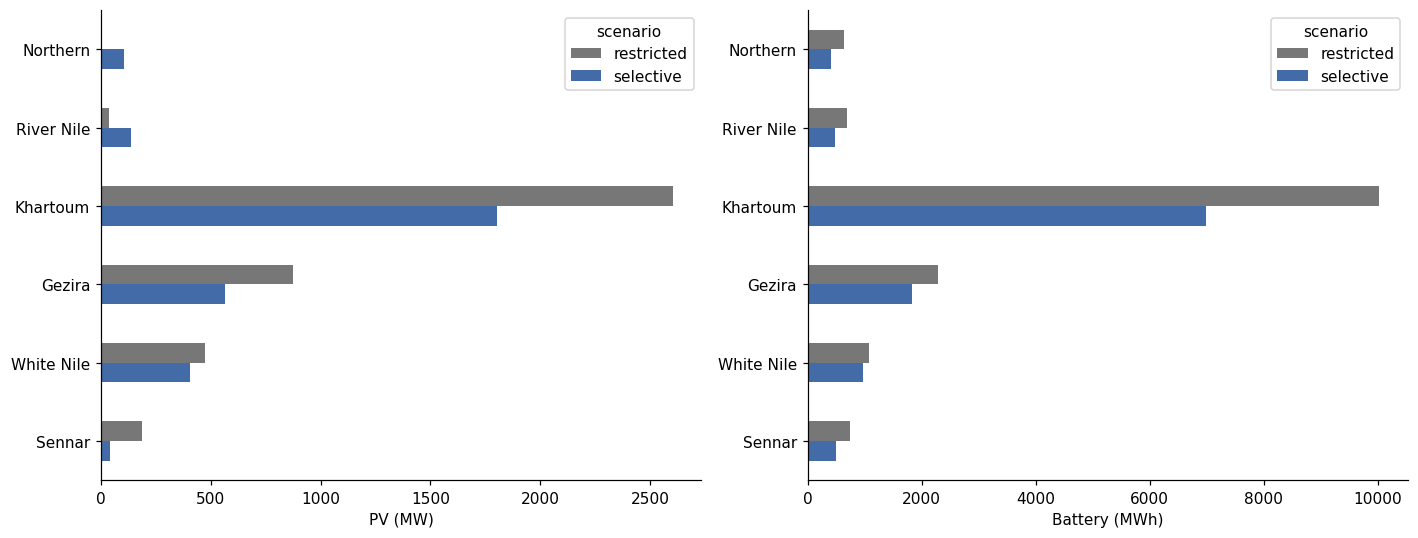

,target_delivered (GWh),pv (GWh),grid (GWh),diesel (GWh),charge (GWh),discharge (GWh)
scenario,,,,,,
restricted,6869.5,6193.2,1773.5,13.6,4676.9,4220.9
selective,6869.5,4600.0,3273.1,7.9,3386.7,3056.5


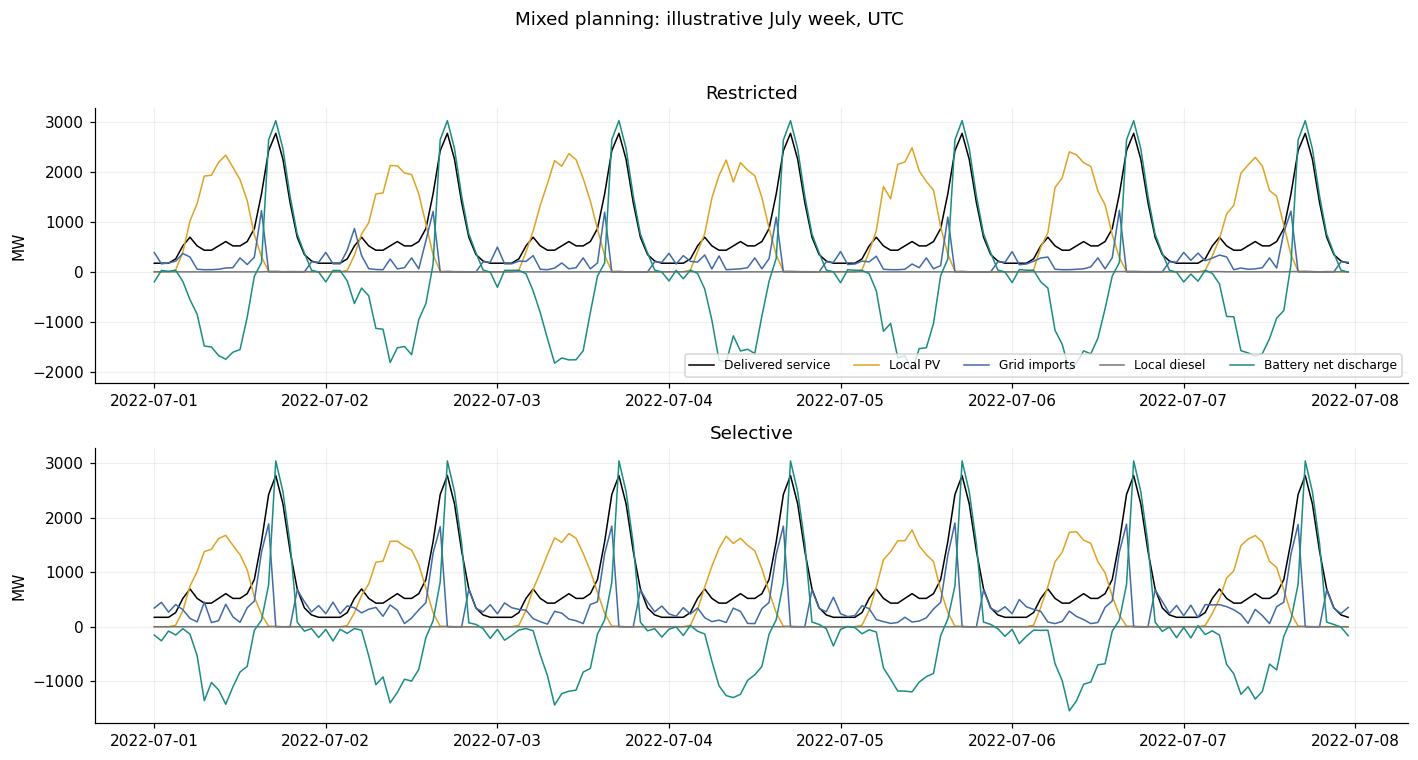

In [6]:
capacity=mixed.groupby(['scenario','state'])[['pv_kWp','battery_nominal_kWh','converter_AC_kW','diesel_kW']].sum()/1000
capacity.columns=['PV (MW)','Battery (MWh)','Converter (MW)','Diesel (MW)']
display(capacity.style.format(precision=1,thousands=','))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,col in zip(axes,['PV (MW)','Battery (MWh)']):
    capacity[col].unstack('scenario').reindex(states)[scenarios].plot.barh(ax=ax,color=['#777777','#426BA7'])
    ax.set_xlabel(col);ax.set_ylabel('');ax.invert_yaxis()
fig.tight_layout();show(fig,'regional_capacities')
energy=pd.read_csv(D/'energy.csv')
display(energy[energy.policy=='mixed'].groupby('scenario')[['target_delivered_MWh','pv_MWh','grid_MWh','diesel_MWh','charge_MWh','discharge_MWh']].sum().div(1000).rename(columns=lambda s:s.replace('_MWh',' (GWh)')).style.format(precision=1))
fig,axes=plt.subplots(2,1,figsize=(13,7))
for ax,scenario in zip(axes,scenarios):
    h=pd.read_csv(D/(scenario+'_hourly.csv.gz'),parse_dates=['time_UTC']).groupby('time_UTC').sum(numeric_only=True).loc['2022-07-01':'2022-07-07']
    for col,label,color in [('target_delivered_MW','Delivered service','black'),('pv_MW','Local PV','#E0A324'),('grid_MW','Grid imports','#426BA7'),('diesel_MW','Local diesel','#777777')]:ax.plot(h.index,h[col],label=label,color=color,lw=1)
    ax.plot(h.index,h.discharge_MW-h.charge_MW,label='Battery net discharge',color='#1C8D82',lw=1)
    ax.set_title(scenario.capitalize());ax.set_ylabel('MW');ax.grid(alpha=.2)
axes[0].legend(ncol=5,fontsize=8);fig.suptitle('Mixed planning: illustrative July week, UTC')
fig.tight_layout(rect=[0,0,1,.95]);show(fig,'hourly_operation')

## 6. What has been validated

All six investments and six separate fixed-investment dispatch replays passed saved-output checks. Tests cover electrical balances, PV availability, chronological storage, converter limits, local grid interruptions, corridor limits, hydro budgets, source coverage, demand allocation and reconstructed costs. All included cases serve the prescribed hourly load without modeled load shedding.

**This demonstrates numerical feasibility for the assumed year, not independently observed demand, war damage, or probabilistic reliability.** The scenario-based findings remain conditional on schematic corridor capacities, proxy distribution routes/transformers, assumed demand, one weather year, historical hydro seasonality and whole-zone technology choices.

In [7]:
display(checks.style.format(precision=10))
display(summary[['scenario','policy','mip_gap','hours','unserved_MWh']].style.format({'mip_gap':'{:.8%}','hours':'{:.0f}','unserved_MWh':'{:.6f}'}))

,case,phase,hours,unserved_MWh,max_bus_balance_error_MW,max_storage_balance_error_MWh,simultaneous_charge_discharge_MWh,passed
0,restricted_mixed_36_d1_f1,investment,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
1,restricted_mixed_36_d1_f1,replay,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
2,restricted_grid_led_36_d1_f1,investment,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
3,restricted_grid_led_36_d1_f1,replay,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
4,restricted_decentralized_36_d1_f1,investment,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
5,restricted_decentralized_36_d1_f1,replay,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
6,selective_mixed_36_d1_f1,investment,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
7,selective_mixed_36_d1_f1,replay,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
8,selective_grid_led_36_d1_f1,investment,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True
9,selective_grid_led_36_d1_f1,replay,8760,0.0000000000,0.0000000000,0.0000000000,0.0000000000,True


,scenario,policy,mip_gap,hours,unserved_MWh
0,restricted,mixed,0.00000000%,8760,0.000000
1,restricted,grid_led,0.00000000%,8760,0.000000
2,restricted,decentralized,0.00000000%,8760,0.000000
3,selective,mixed,0.00016924%,8760,0.000000
4,selective,grid_led,0.00000000%,8760,0.000000
5,selective,decentralized,0.00000000%,8760,0.000000


## 7. What remains before the full study

- Restored recovery: mixed, grid-led and decentralized-first policies.
- Selective recovery checks: 48 zones, +20% residential service demand and +25% fuel prices.
- Cross-case checks and the complete 12-case notebook.

These six completed cases already support comparisons within restricted and selective recovery. They do not yet establish the results for restored recovery or whether the geographic choices survive the planned robustness checks.

The main batch continues independently. This interim notebook is a frozen snapshot and is not overwritten by the final report. Its data and source-manifest hashes are recorded in `snapshot.json`. Rebuild it from the repository root with `python research/regional_joint_study/interim_report.py`; no solver is invoked. The broader methods and sources remain in [the study guide](../README.md), [regional documentation](../../../docs/REGIONAL_MODEL.md) and [cost evidence](../../../data/system_costs/README.md).